<a href="https://colab.research.google.com/github/mimrancomsats/ProgramingforAI_FALL26/blob/main/Lab_8_EDA%2BML_using_LLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EDA + ML using LLM**
* ChatGPT LLM
* Scikit LLM


Code: df['Age'].hist()
Result: Axes(0.125,0.11;0.775x0.77)


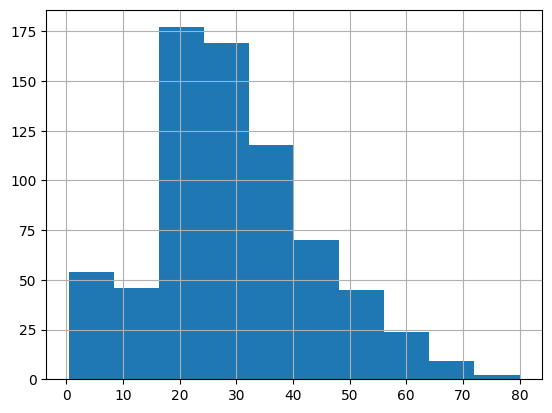

In [2]:
import pandas as pd
from openai import OpenAI

# 1. Setup Data & Client (uses OPENAI_API_KEY from environment/Colab Secrets)
#df = pd.DataFrame([
    #('John Doe', 25, 50), ('Jane Smith', 38, 70),
    #('Alex Johnson', 45, 80), ('Jessica Brown', 60, 40),
    #('Michael Davis', 22, 90), ('Emily Wilson', 30, 60),
    #('Daniel Taylor', 35, 75), ('Sophia Moore', 40, 85),
    #('David Thomas', 50, 65), ('Olivia Jackson', 29, 55)
#], columns=['name', 'age', 'donation'])
df = pd.read_csv("titanic.csv")

api_key = "<>"

client = OpenAI(api_key=api_key)

# 2. Ask OpenAI for the pandas expression
#question = "What is the average donation of people older than 40 who donated more than $50?"
question = "Create histogram for the age feature"
res = client.responses.create(
    model="gpt-4.1-mini",
    instructions="Return ONLY a single-line Python pandas expression using `df` (no markdown, no variable assignment).",
    input=f"Columns: {list(df.columns)}\nQuestion: {question}"
)

# 3. Evaluate and print
code = res.output_text.strip()
print(f"Code: {code}\nResult: {eval(code)}")


In [7]:
!pip install -q google-genai

Generated Pandas expression:
df['Age'].hist()

Result:
Axes(0.125,0.11;0.775x0.77)


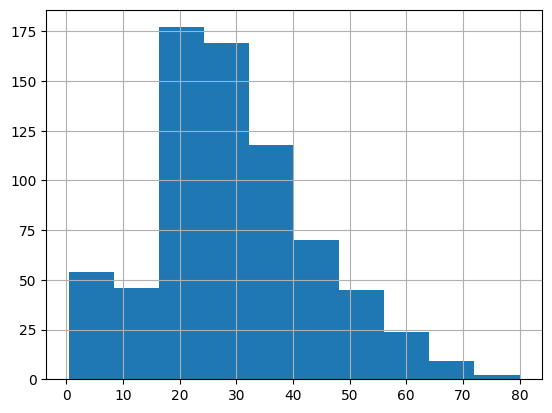

In [12]:
import pandas as pd
from google import genai

# 1. Load Titanic dataset
df = pd.read_csv("titanic.csv")

# 3. Initialize Gemini client
client = genai.Client(api_key="<>")

# 4. Define natural-language question
question = "Create histogram for the age feature"

# 5. Ask Gemini to generate a Pandas expression
res = client.models.generate_content(
    model="gemini-3.7-flash",
    contents=f"""
    Return ONLY a single-line Python pandas expression
    using `df`. Do not include markdown or variable assignment.

    Columns: {list(df.columns)}
    Question: {question}
    """
)

# 6. Extract generated expression
code = res.text.strip()

print("Generated Pandas expression:")
print(code)

# 7. Execute and display result
result = eval(code, {"df": df})

print("\nResult:")
print(result)


In [9]:
!pip install -q anthropic

Generated code: df['Age'].plot(kind='hist', bins=10, title='Age Distribution')
Result: Axes(0.125,0.11;0.775x0.77)


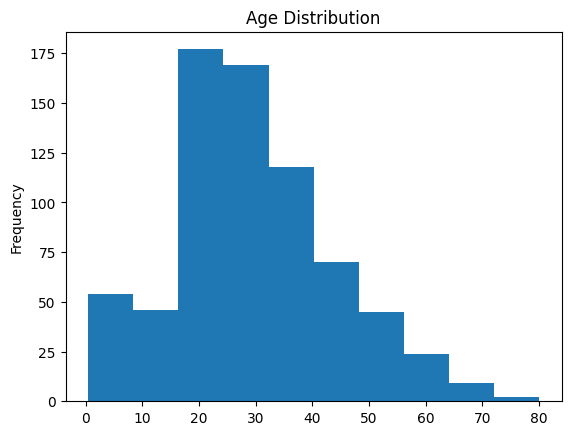

In [10]:

import pandas as pd
from anthropic import Anthropic

df = pd.read_csv("titanic.csv")

client = Anthropic(api_key="<>")

question = "Create histogram for the age feature"

res = client.messages.create(
    model="claude-sonnet-4-6",
    max_tokens=300,
    messages=[
        {
            "role": "user",
            "content": f"Generate only a Python pandas expression using df. Columns: {list(df.columns)}. Do not include markdown or variable assignment. Question: {question}"
        }
    ]
)

code = res.content[0].text.strip()
print("Generated code:", code)

# Remove Markdown code fences if generated
# code = code.replace("```python", "").replace("```", "").strip()

result = eval(code, {"df": df})
print("Result:", result)


# Lab Task

* Get your OpenAI and Gemini API keys, and execute the above code.
* Modify the prompt and analyze the LLM's responses to various prompts.
* Apply EDA using an LLM on the following dataset.

https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease

* Explore how we can use ScikitLLM for making predictions.
* Exlpore the PandasAI library (https://pypi.org/project/pandasai/) and determine how it is more convinient than using individual LLM libraries.  
* Develop a Streamlit-based frontend that allows users to upload datasets and ask questions about the uploaded data.